# Hands-on

We extract the characteristics of rooftop PV polygons detected by
[DeepPVMapper](https://github.com/gabrielkasmi/deeppvmapper) in the Rhône
department (`arrays_69.geojson`, from our
[Zenodo repository](https://doi.org/10.5281/zenodo.7586879)), with:

1. the **classic methods** (look-up table for the tilt, bounding box for the azimuth);
2. **elevation models**: the tilt and azimuth of the roof plane under each polygon are
   measured on the IGN LiDAR HD surface model, queried on the fly, and compared with the
   IGN MNS Correl and with a local surface model;
3. a **visual check** of a few polygons.

Steps 2 and 3 query the IGN Géoplateforme (internet access needed, France only).
Azimuths are in degrees, **0 = north, clockwise** (180 = south).

In [1]:
import os, urllib.request, zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pypvroof import (MetadataExtraction, characterize_roofs,
                      IGNLidarService, IGNCorrelService, LocalRasterService)
from pypvroof.geometry import to_geodataframe
from pypvroof.viz import plot_polygon

BLUE, ORANGE = "#257de0", "#f47230"

In [2]:
# Download the hands-on data (34 MB) once
data_dir = "hands-on"
if not os.path.isdir(data_dir):
    urllib.request.urlretrieve("https://zenodo.org/record/7586879/files/hands-on.zip?download=1", "hands-on.zip")
    zipfile.ZipFile("hands-on.zip").extractall(".")
    os.remove("hands-on.zip")
sorted(os.listdir(data_dir))

['arrays_69.geojson', 'bdappv-metadata.csv', 'lookup-table.json', 'tile.tif']

In [3]:
# Any geo input works: a path, a GeoJSON dict, a GeoDataFrame...
arrays = to_geodataframe(os.path.join(data_dir, "arrays_69.geojson"))
print(len(arrays), "polygons,", arrays.crs)
arrays.head()

3584 polygons, EPSG:4326


,tile,geometry
0,69-2020-0815-6525-LA93-0M20-E080,"POLYGON ((4.50294 45.77095, 4.50294 45.77091, ..."
1,69-2020-0815-6525-LA93-0M20-E080,"POLYGON ((4.49852 45.77136, 4.49851 45.77135, ..."
2,69-2020-0815-6525-LA93-0M20-E080,"POLYGON ((4.4984 45.77149, 4.4984 45.77146, 4...."
3,69-2020-0815-6525-LA93-0M20-E080,"POLYGON ((4.54146 45.77148, 4.54146 45.77148, ..."
4,69-2020-0815-6525-LA93-0M20-E080,"POLYGON ((4.50092 45.77254, 4.50091 45.77253, ..."


## 1. Classic methods

`MetadataExtraction` with the look-up table (tilt), the bounding box (azimuth) and the
clustered regression (installed capacity), for all the polygons.

In [4]:
params = {
    "tilt-method": "lut",
    "azimuth-method": "bounding-box",
    "regression-type": "clustered",
    "regression-clusters": 4,
}
classic = MetadataExtraction(p=params).extract_all_characteristics(arrays)
classic.head()

,lon,lat,tilt,azimuth,installed_capacity,surface
0,4.502993,45.770910,21.562500,181.594560,5.322853,41.075876
1,4.498503,45.771343,23.854167,171.528083,2.878914,18.727282
2,4.498419,45.771448,21.562500,263.488439,3.374701,26.042198
3,4.541472,45.771458,20.833333,180.000000,2.986753,21.696709
4,4.500932,45.772514,21.562500,90.000000,3.110223,22.593638


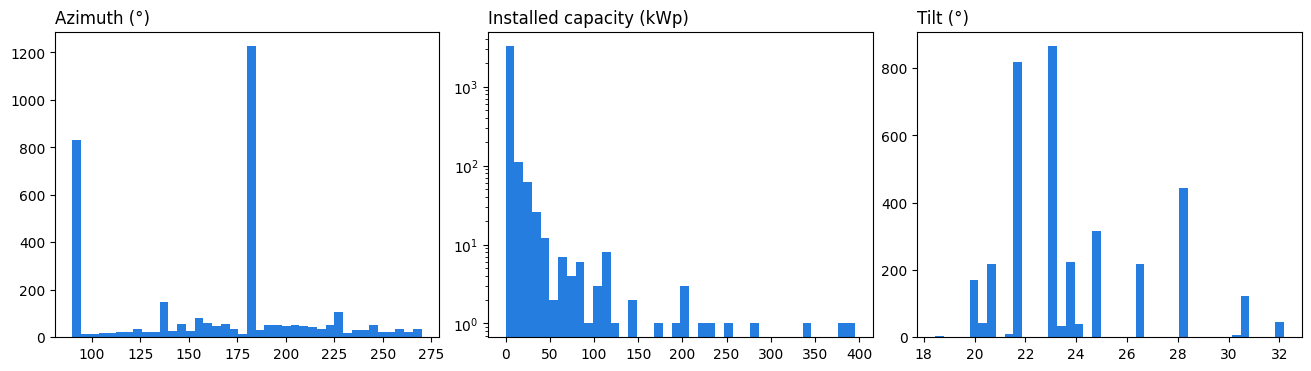

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for a, col, title in zip(ax, ["azimuth", "installed_capacity", "tilt"],
                         ["Azimuth (°)", "Installed capacity (kWp)", "Tilt (°)"]):
    a.hist(classic[col].dropna(), bins=40, color=BLUE)
    a.set_title(title, loc="left")
ax[1].set_yscale("log")
plt.show()

The bounding box can only tell the *axis* of the installation: it returns the normal
closest to south. The look-up table gives one tilt per (location, surface class) cell.

## 2. Tilt and azimuth measured on the elevation models

`characterize_roofs` fetches the elevation grid under each polygon (one small request
per polygon), fits the roof plane(s) and returns a GeoDataFrame with a `status` per
polygon. We work on a random sample of 300 polygons to keep the demo fast.

In [6]:
sample = arrays.sample(300, random_state=0)
lidar = characterize_roofs(sample, IGNLidarService(), workers=8)
lidar["status"].value_counts()

status
ok                214
flat               43
too_few_points     33
multimodal         10
Name: count, dtype: int64

In [7]:
lidar[["tilt", "azimuth", "status", "inspect", "surface_proj", "surface",
       "meta_date_fin_acquisition"]].head(10)

,tilt,azimuth,status,inspect,surface_proj,surface,meta_date_fin_acquisition
0,19.944235,129.162591,ok,False,10.460487,11.127881,2022-07-05
1,NaN,NaN,too_few_points,False,2.464495,NaN,2022-07-05
2,14.617838,214.343441,ok,False,56.085339,57.961516,2022-07-05
3,2.717165,NaN,flat,False,6.110704,6.117582,2021-04-14
4,NaN,NaN,multimodal,True,28.335028,NaN,2022-07-11
5,18.232593,207.316342,ok,False,23.996209,25.264640,2022-07-05
6,0.608840,NaN,flat,False,10.426996,10.427585,2022-07-05
7,0.406332,NaN,flat,False,21.342922,21.343458,2022-07-05
8,NaN,NaN,multimodal,True,61.158516,NaN,2021-04-14
9,0.870925,NaN,flat,False,55.420933,55.427337,2021-09-24


Statuses: `ok` (one roof plane), `flat` (azimuth undefined), `multimodal` (several roof
planes under the polygon, flagged with `inspect=True`), `too_few_points` (tiny polygon),
`no_coverage` (no data at this location)... No fallback is applied: the caller decides.
The `meta_*` columns come from the service (here, the LiDAR acquisition dates).

### Comparison with the classic methods

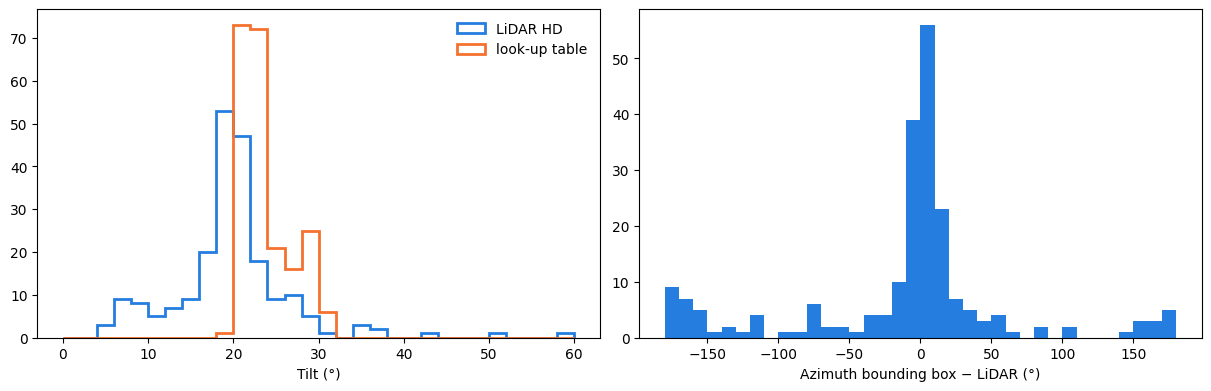

tilt: mean |LUT − LiDAR| = 6.5°
azimuth: 21% of the bounding-box azimuths point the wrong way


In [8]:
cmp = classic.loc[sample.index].assign(tilt_lidar=lidar["tilt"].values,
                                       az_lidar=lidar["azimuth"].values,
                                       status=lidar["status"].values)
ok = cmp[cmp.status == "ok"]
d_az = ((ok.azimuth - ok.az_lidar + 180) % 360) - 180

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
bins = np.arange(0, 62, 2)
ax[0].hist(ok.tilt_lidar, bins=bins, histtype="step", lw=2, color=BLUE, label="LiDAR HD")
ax[0].hist(ok.tilt, bins=bins, histtype="step", lw=2, color=ORANGE, label="look-up table")
ax[0].set_xlabel("Tilt (°)"); ax[0].legend(frameon=False)
ax[1].hist(d_az, bins=np.arange(-180, 181, 10), color=BLUE)
ax[1].set_xlabel("Azimuth bounding box − LiDAR (°)")
plt.show()
print(f"tilt: mean |LUT − LiDAR| = {(ok.tilt - ok.tilt_lidar).abs().mean():.1f}°")
print(f"azimuth: {(d_az.abs() > 90).mean():.0%} of the bounding-box azimuths point the wrong way")

### MNS Correl

The IGN MNS Correl is computed from the BD ORTHO aerial images (the images the polygons
were detected on). It covers areas without LiDAR HD, but is less precise.

In [9]:
correl = characterize_roofs(sample, IGNCorrelService(), workers=8)
both = (lidar["status"].values == "ok") & (correl["status"].values == "ok")
d = correl["tilt"].values[both] - lidar["tilt"].values[both]
print(f"{both.sum()} polygons ok with both: median difference {np.median(d):+.1f}°, "
      f"|difference| < 5° for {(np.abs(d) < 5).mean():.0%}")
pd.crosstab(lidar["status"].values, correl["status"].values, rownames=["LiDAR"], colnames=["Correl"])

180 polygons ok with both: median difference -1.3°, |difference| < 5° for 58%


Correl,flat,multimodal,ok,too_few_points
LiDAR,,,,
flat,24,4,15,0
multimodal,3,4,3,0
ok,17,17,180,0
too_few_points,0,0,0,33


### Splitting polygons that cover several roof planes

With `split=True`, a `multimodal` polygon is split into parts that are homogeneous in
tilt and azimuth (rows sharing a `parent_id`).

In [10]:
multi = lidar[lidar.status == "multimodal"]
if len(multi):
    parts = characterize_roofs(sample.loc[multi.parent_id], IGNLidarService(), split=True, workers=8)
    display(parts[["parent_id", "part", "tilt", "azimuth", "status", "surface_proj"]].head(10))

,parent_id,part,tilt,azimuth,status,surface_proj
0,3564,0,0.743153,NaN,flat,12.962396
1,3564,1,15.204278,242.311711,ok,15.372632
2,1374,0,13.767665,145.621979,ok,36.865684
3,1374,1,30.637665,145.162012,ok,24.292832
4,346,0,21.138080,10.074979,ok,4.622880
5,346,1,20.998968,186.765564,ok,4.075179
6,1798,0,15.029531,261.346556,ok,79.960263
7,1798,1,10.631435,172.697744,ok,41.094853
8,728,0,15.512891,340.896710,ok,12.489855
9,728,1,3.537852,NaN,flat,8.906005


### Local elevation models

The same estimation runs on local rasters: single-band GeoTIFFs whose pixel values are
elevations (metres), in a projected CRS. The hands-on folder ships a 10 cm surface model
over a 400 m × 400 m area of Lyon (`tile.tif`).

In [11]:
local = LocalRasterService(data_dir)
inside = arrays[arrays.to_crs(2154).within(__import__("shapely").box(*local._boxes[0].bounds))]
loc = characterize_roofs(inside, local, workers=8)
lid = characterize_roofs(inside, IGNLidarService(fetch_metadata=False), workers=8)
pd.DataFrame({"status_local": loc.status.values, "tilt_local": loc.tilt.values.round(1),
              "status_lidar": lid.status.values, "tilt_lidar": lid.tilt.values.round(1)}).head(10)

,status_local,tilt_local,status_lidar,tilt_lidar
0,ok,19.9,ok,20.2
1,ok,19.8,too_few_points,NaN
2,ok,20.5,ok,20.7
3,too_few_points,NaN,too_few_points,NaN


### Through `MetadataExtraction`

The `theil-sen` method plugs the same engine into `MetadataExtraction`, so that the
installed capacity uses the measured tilt.

In [12]:
params_dsm = dict(params, **{"tilt-method": "theil-sen", "azimuth-method": "theil-sen",
                             "dsm-service": "ign", "workers": 8})
measured = MetadataExtraction(p=params_dsm).extract_all_characteristics(sample.head(50))
measured[["tilt", "azimuth", "installed_capacity", "surface", "status"]].head()

,tilt,azimuth,installed_capacity,surface,status
0,19.944235,129.162591,1.713356,11.145351,ok
1,NaN,NaN,NaN,NaN,too_few_points
2,14.617838,214.343441,7.522845,58.052981,ok
3,2.717165,NaN,0.941913,6.127128,flat
4,NaN,NaN,NaN,NaN,multimodal


## 3. Visual check

`plot_polygon` shows the orthophoto and the elevation models under a polygon, with the
estimated tilt and azimuth.

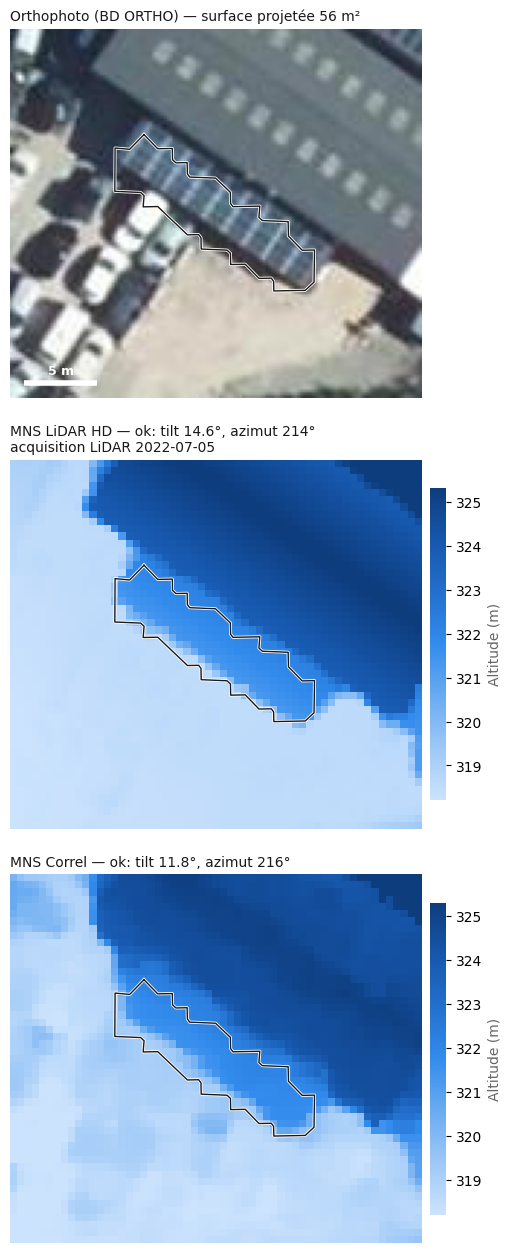

In [13]:
example = lidar[(lidar.status == "ok") & lidar.surface_proj.between(20, 60)].parent_id.iloc[0]
fig = plot_polygon(sample.loc[[example]], services=("ign", "ign-correl"))
plt.show()

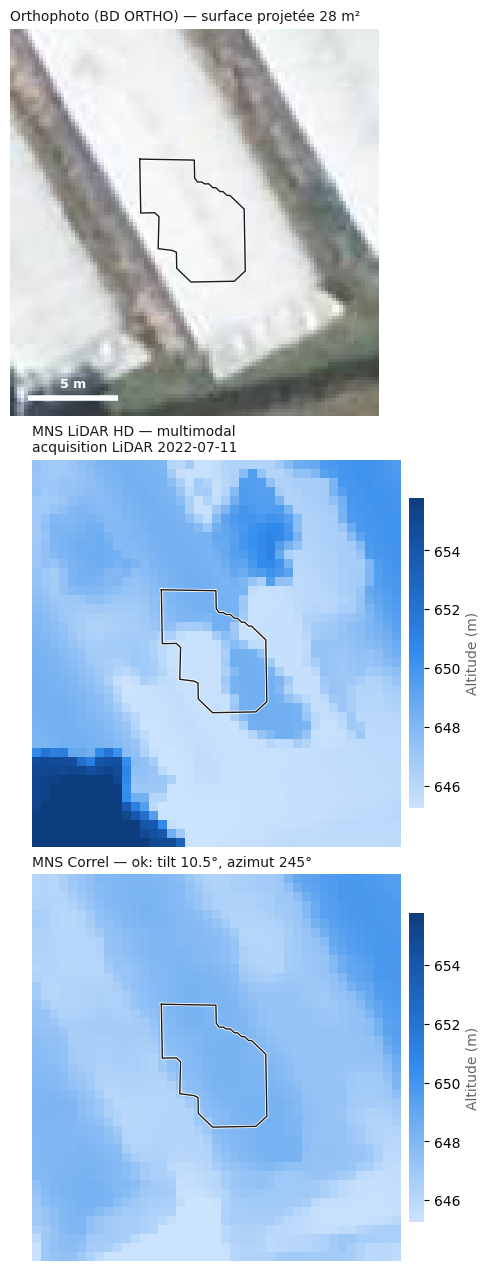

In [14]:
if len(multi):
    fig = plot_polygon(sample.loc[[multi.parent_id.iloc[0]]], services=("ign", "ign-correl"))
    plt.show()